# Search algorithms and held-out decisions

Sequential TPE and random search propose parameters for the same audited factor model. The common initial proposals, budget, selection role and unfavorable results make this a meaningful search comparison.

In [1]:
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
ROOT=Path.cwd()
if ROOT.name == "notebooks": ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/"src"))
def read(name): return json.loads((ROOT/name).read_text())


## Check shared startup proposals

In [2]:
histories={}
for seed in [0,1,2]:
    for strategy in ["random","tpe"]:
        metrics=read(f"results/reference/adaptive_search/{strategy}/seed{seed}/metrics.json")
        histories[strategy,seed]=metrics
    assert [t["parameters"] for t in histories["random",seed]["trials"][:8]] == [t["parameters"] for t in histories["tpe",seed]["trials"][:8]]
print("All three shared startup sequences match")

All three shared startup sequences match


## Recompute validation selection

In [3]:
for key,metrics in histories.items():
    selected=min(metrics["trials"],key=lambda t:(t["validation_rmse"],t["number"]))
    assert selected["number"] == metrics["selected_trial"]
    assert selected["parameters"] == metrics["selected_parameters"]
    assert len(metrics["trials"]) == 16
print("All six winners selected without test metrics")

All six winners selected without test metrics


## Every selected deployment result

In [4]:
frame=pd.read_csv(ROOT/"docs/adaptive_search_fits.csv")
assert len(frame)==6
frame.groupby("strategy")[["validation_rmse","test_rmse"]].agg(["mean","std"])

validation_rmse           test_rmse          
                    mean       std      mean       std
strategy                                              
random          0.915880  0.001725  0.936911  0.000979
tpe             0.915628  0.001253  0.937808  0.001819

## Validation trajectories and interpretation

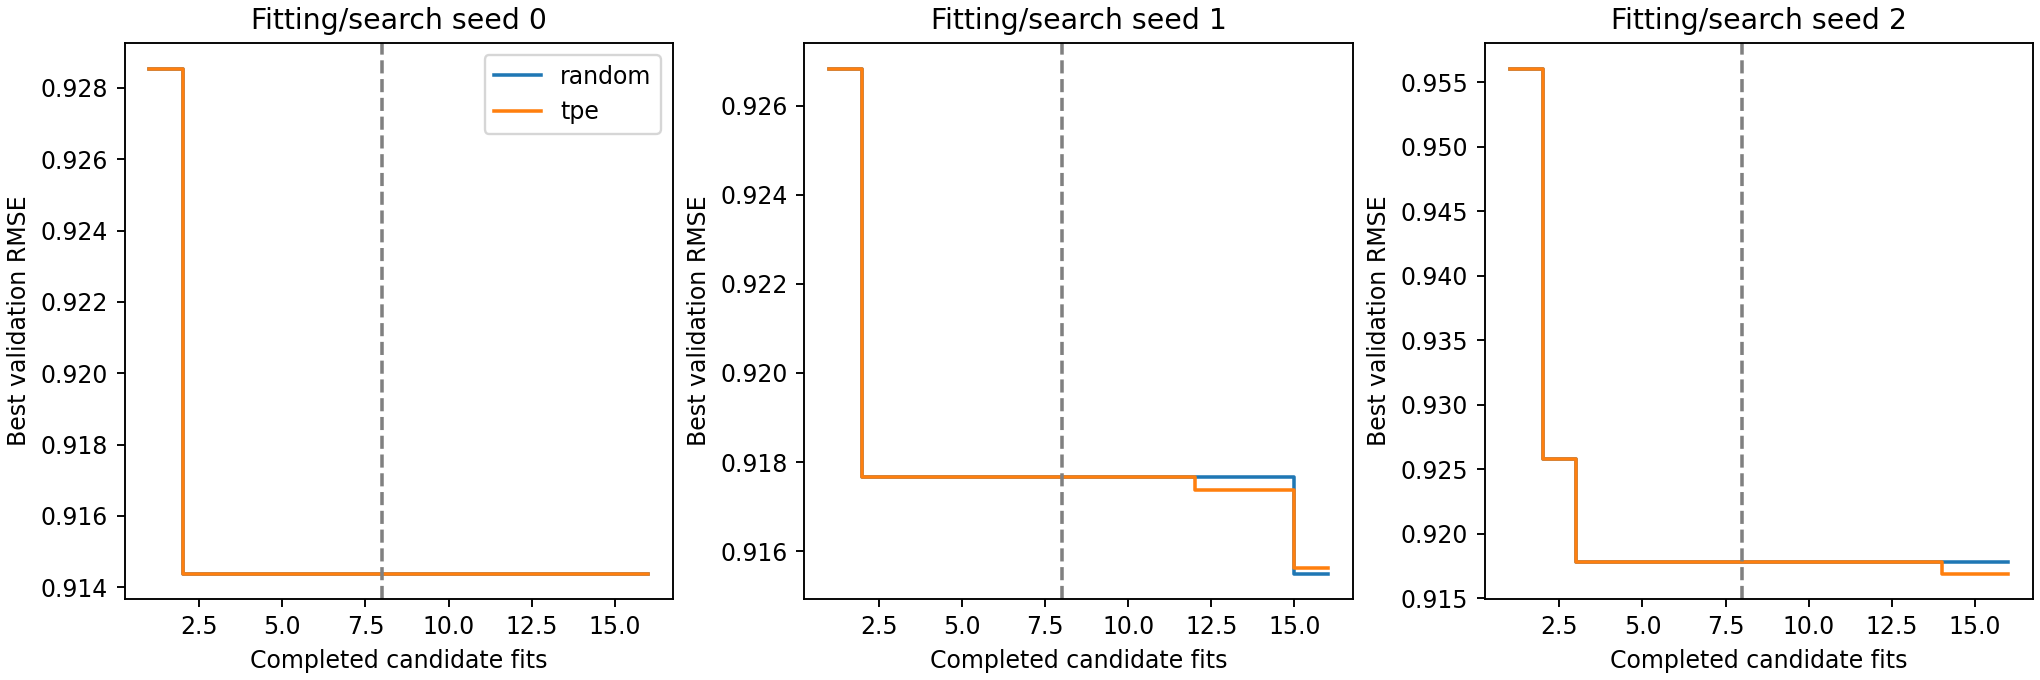

A small density-model search need not beat random search. Epoch selection and parameter selection share validation; the official test remains reserved until each campaign completes.


In [5]:
display(Image(filename=str(ROOT/"assets/figures/adaptive_search.png")))
print("A small density-model search need not beat random search. Epoch selection and parameter selection share validation; the official test remains reserved until each campaign completes.")

## Exercise and worked interpretation

Change the modeling or budget assumption and identify which claim survives. A feasible TV dual remains a lower bound for its stated objective; it does not guarantee improved PSNR. A validation winner remains the winner of its declared candidates; a larger search can still overfit selection. A route certificate uses the exact integer metric, while a visual map is only a display. Keep these claims separate when interpreting the result.